In [1]:
import os
import sys
import shutil
import subprocess
from pathlib import Path

print("Python:", sys.version)
print("Working directory:", Path.cwd())

print("\nGPU:")
subprocess.run(["nvidia-smi"], check=False)

print("\nDisk:")
subprocess.run(["df", "-h", "/content"], check=False)

print("\nExisting SF3D paths:")
for path in [
    "/content/miniforge3",
    "/content/sf3d-env",
    "/content/stable-fast-3d",
    "/content/cuda-12.1",
]:
    print(("✅" if Path(path).exists() else "❌"), path)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Working directory: /content

GPU:

Disk:

Existing SF3D paths:
❌ /content/miniforge3
❌ /content/sf3d-env
❌ /content/stable-fast-3d
❌ /content/cuda-12.1


In [2]:
import os
import sys
import subprocess
from pathlib import Path

ROOT = Path("/content")
MF = ROOT / "miniforge3"
ENV = ROOT / "sf3d-env"
INSTALLER = ROOT / "Miniforge3-Linux-x86_64.sh"

if not MF.exists():
    subprocess.run(
        [
            "wget", "-q",
            "https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh",
            "-O", str(INSTALLER),
        ],
        check=True,
    )
    subprocess.run(
        ["bash", str(INSTALLER), "-b", "-p", str(MF)],
        check=True,
    )

CONDA = MF / "bin" / "conda"

if not ENV.exists():
    subprocess.run(
        [
            str(CONDA), "create", "-y",
            "-p", str(ENV),
            "python=3.10",
            "pip",
            "setuptools==69.5.1",
            "wheel",
            "ninja",
            "gcc_linux-64=11",
            "gxx_linux-64=11",
            "-c", "conda-forge",
        ],
        check=True,
    )

PY = ENV / "bin" / "python"

subprocess.run([str(PY), "--version"], check=True)
subprocess.run([str(PY), "-m", "pip", "--version"], check=True)

print("\n✅ Clean SF3D environment created:", ENV)


✅ Clean SF3D environment created: /content/sf3d-env


In [3]:
import subprocess
from pathlib import Path

ENV = Path("/content/sf3d-env")
PY = ENV / "bin" / "python"
PIP = ENV / "bin" / "pip"

subprocess.run(
    [
        str(PIP), "install", "--upgrade",
        "pip==24.3.1",
        "setuptools==69.5.1",
        "wheel",
    ],
    check=True,
)

subprocess.run(
    [
        str(PIP), "install",
        "torch==2.4.1",
        "torchvision==0.19.1",
        "--index-url", "https://download.pytorch.org/whl/cu121",
    ],
    check=True,
)

subprocess.run(
    [
        str(PY), "-c",
        """
import torch
print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError("No GPU detected. In Colab select Runtime → Change runtime type → T4 GPU.")
print("GPU:", torch.cuda.get_device_name(0))
""",
    ],
    check=True,
)

print("\n✅ Matching PyTorch CUDA environment is ready.")


✅ Matching PyTorch CUDA environment is ready.


In [4]:
import os
import subprocess
from pathlib import Path

ROOT = Path("/content")
CUDA_HOME = ROOT / "cuda-12.1"
INSTALLER = ROOT / "cuda_12.1.1_linux.run"

if not (CUDA_HOME / "bin" / "nvcc").exists():
    subprocess.run(
        [
            "wget", "-q",
            "https://developer.download.nvidia.com/compute/cuda/12.1.1/local_installers/cuda_12.1.1_530.30.02_linux.run",
            "-O", str(INSTALLER),
        ],
        check=True,
    )

    # --override is required because Colab's system GCC is newer than CUDA 12.1 expects.
    subprocess.run(
        [
            "sh", str(INSTALLER),
            "--silent",
            "--toolkit",
            f"--toolkitpath={CUDA_HOME}",
            "--no-opengl-libs",
            "--override",
        ],
        check=True,
    )

subprocess.run([str(CUDA_HOME / "bin" / "nvcc"), "--version"], check=True)

print("\n✅ Standalone CUDA compiler ready:", CUDA_HOME)


✅ Standalone CUDA compiler ready: /content/cuda-12.1


In [5]:
import os
import subprocess
from pathlib import Path

ROOT = Path("/content")
ENV = ROOT / "sf3d-env"
PY = ENV / "bin" / "python"
PIP = ENV / "bin" / "pip"
REPO = ROOT / "stable-fast-3d"

if not REPO.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/Stability-AI/stable-fast-3d.git",
            str(REPO),
        ],
        check=True,
    )

# Read official requirements but exclude the two local CUDA extension packages.
requirements = []
for raw_line in (REPO / "requirements.txt").read_text().splitlines():
    line = raw_line.strip()
    if not line or line.startswith("#"):
        continue
    if "texture_baker" in line or "uv_unwrapper" in line:
        continue
    requirements.append(line)

print("Installing official non-extension requirements:")
print("\n".join(requirements))

subprocess.run(
    [str(PIP), "install", "--upgrade", *requirements],
    cwd=str(REPO),
    check=True,
)

# Essential packages used by SF3D and later API validation.
subprocess.run(
    [
        str(PY), "-c",
        """
import torch, trimesh, einops, omegaconf, rembg
print("Torch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("✅ SF3D Python dependencies imported successfully")
""",
    ],
    cwd=str(REPO),
    check=True,
)

print("\n✅ Official SF3D source and Python dependencies are ready.")

Installing official non-extension requirements:
einops==0.7.0
jaxtyping==0.2.31
omegaconf==2.3.0
transformers==4.42.3
open_clip_torch==2.24.0
trimesh==4.4.1
numpy==1.26.4
huggingface-hub==0.23.4
rembg[gpu]==2.0.57; sys_platform != 'darwin'
rembg==2.0.57; sys_platform == 'darwin'
pynanoinstantmeshes==0.0.3
gpytoolbox==0.2.0

✅ Official SF3D source and Python dependencies are ready.


In [6]:
import os
import subprocess
from pathlib import Path

ROOT = Path("/content")
ENV = ROOT / "sf3d-env"
REPO = ROOT / "stable-fast-3d"
CUDA_HOME = ROOT / "cuda-12.1"

PY = ENV / "bin" / "python"
PIP = ENV / "bin" / "pip"

assert (CUDA_HOME / "bin" / "nvcc").exists()
assert (CUDA_HOME / "include" / "nv" / "target").exists()

build_env = os.environ.copy()
build_env["CUDA_HOME"] = str(CUDA_HOME)
build_env["CUDA_PATH"] = str(CUDA_HOME)
build_env["CUDACXX"] = str(CUDA_HOME / "bin" / "nvcc")
build_env["PATH"] = f"{CUDA_HOME / 'bin'}:{ENV / 'bin'}:{build_env['PATH']}"
build_env["LD_LIBRARY_PATH"] = (
    f"{CUDA_HOME / 'lib64'}:{ENV / 'lib'}:"
    + build_env.get("LD_LIBRARY_PATH", "")
)
build_env["CC"] = str(ENV / "bin" / "x86_64-conda-linux-gnu-gcc")
build_env["CXX"] = str(ENV / "bin" / "x86_64-conda-linux-gnu-g++")
build_env["TORCH_CUDA_ARCH_LIST"] = "7.5"
build_env["MAX_JOBS"] = "1"

subprocess.run([str(CUDA_HOME / "bin" / "nvcc"), "--version"], env=build_env, check=True)

for package in ["texture_baker", "uv_unwrapper"]:
    print(f"\n{'=' * 65}\nBuilding official extension: {package}\n{'=' * 65}")
    subprocess.run(
        [
            str(PIP), "install",
            "--no-build-isolation",
            "--no-deps",
            f"./{package}",
        ],
        cwd=str(REPO),
        env=build_env,
        check=True,
    )

subprocess.run(
    [
        str(PY), "-c",
        """
from texture_baker import TextureBaker
from uv_unwrapper import Unwrapper
from sf3d.system import SF3D
print("✅ texture_baker import: SUCCESS")
print("✅ uv_unwrapper import: SUCCESS")
print("✅ official SF3D import: SUCCESS")
""",
    ],
    cwd=str(REPO),
    env=build_env,
    check=True,
)

print("\n✅ SF3D is fully installed and ready for weights.")


Building official extension: texture_baker

Building official extension: uv_unwrapper

✅ SF3D is fully installed and ready for weights.


In [7]:
import os
import getpass
import subprocess
from pathlib import Path

ROOT = Path("/content")
ENV = ROOT / "sf3d-env"
REPO = ROOT / "stable-fast-3d"
PY = ENV / "bin" / "python"

token = getpass.getpass(
    "Paste your Hugging Face READ token (input stays hidden): "
).strip()

if not token.startswith("hf_"):
    raise ValueError("Use a Hugging Face READ token beginning with hf_.")

run_env = os.environ.copy()
run_env["HF_TOKEN"] = token
run_env["HF_HOME"] = str(ROOT / "hf-cache")
run_env["CUDA_HOME"] = str(ROOT / "cuda-12.1")
run_env["PATH"] = f"{ROOT / 'cuda-12.1' / 'bin'}:{ENV / 'bin'}:{run_env['PATH']}"
run_env["LD_LIBRARY_PATH"] = (
    f"{ROOT / 'cuda-12.1' / 'lib64'}:{ENV / 'lib'}:"
    + run_env.get("LD_LIBRARY_PATH", "")
)

check_code = """
import torch
from sf3d.system import SF3D

print("Downloading/loading official SF3D weights...")
model = SF3D.from_pretrained(
    "stabilityai/stable-fast-3d",
    config_name="config.yaml",
    weight_name="model.safetensors",
)
model.to("cuda").eval()

print("✅ Official SF3D weights loaded")
print("Device:", next(model.parameters()).device)
print("CUDA memory (MB):", round(torch.cuda.memory_allocated() / 1024**2, 1))
"""

subprocess.run(
    [str(PY), "-c", check_code],
    cwd=str(REPO),
    env=run_env,
    check=True,
)

print("\n✅ Weights are cached for this Colab session.")

Paste your Hugging Face READ token (input stays hidden): ··········

✅ Weights are cached for this Colab session.


In [8]:
import sys
import subprocess
import torch

subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q", "--upgrade",
        "diffusers==0.42.1",
        "transformers==5.21.0",
        "accelerate",
        "safetensors",
        "huggingface_hub==1.33.0",
        "pillow",
    ],
    check=True,
)

import diffusers
import transformers
import huggingface_hub

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)
print("✅ ControlNet libraries are ready")

Torch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Diffusers: 0.42.1
Transformers: 5.21.0
Hugging Face Hub: 1.33.0
✅ ControlNet libraries are ready


In [9]:
import gc
import torch
import numpy as np
from PIL import Image, ImageOps, ImageFilter
from diffusers import ControlNetModel, StableDiffusionControlNetPipeline

DEVICE = "cuda"
DTYPE = torch.float16

print("Loading ControlNet Scribble...")
controlnet = ControlNetModel.from_pretrained(
    "lllyasviel/sd-controlnet-scribble",
    dtype=DTYPE,
)

pipe = StableDiffusionControlNetPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet,
    dtype=DTYPE,
    safety_checker=None,
).to(DEVICE)

pipe.enable_attention_slicing()

def prepare_scribble(image_path, size=512):
    """Creates a clean black-on-white sketch control image."""
    image = Image.open(image_path).convert("RGB")
    image = ImageOps.contain(image, (size, size), Image.Resampling.LANCZOS)

    canvas = Image.new("RGB", (size, size), "white")
    x = (size - image.width) // 2
    y = (size - image.height) // 2
    canvas.paste(image, (x, y))

    gray = np.array(ImageOps.grayscale(canvas))
    # Preserve dark drawing lines; remove light paper/background.
    scribble = np.where(gray < 210, 0, 255).astype(np.uint8)
    return Image.fromarray(scribble, "L").convert("RGB")

def make_clay_guide(
    sketch_path,
    output_path,
    prompt="a single centered three-dimensional object, neutral gray clay material, studio lighting, plain light background",
    seed=2026,
):
    control = prepare_scribble(sketch_path)

    full_prompt = (
        f"{prompt}. Preserve the drawing silhouette, proportions, and visible parts. "
        "No text, no watermark, no extra objects."
    )

    generator = torch.Generator(device=DEVICE).manual_seed(seed)

    result = pipe(
        prompt=full_prompt,
        image=control,
        num_inference_steps=30,
        guidance_scale=7.5,
        controlnet_conditioning_scale=1.3,
        generator=generator,
    ).images[0]

    output_path = str(output_path)
    result.save(output_path)

    print("✅ Clay guide saved:", output_path)
    return result, control

print("✅ make_clay_guide() is ready")

Loading ControlNet Scribble...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.controlnet.pipeline_controlnet.StableDiffusionControlNetPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


✅ make_clay_guide() is ready


Upload 1 to 4 single-object sketch images now.


Saving cup-outline-coloring-book-page-line-art-illustration-digital-drawing_871209-9844.avif to cup-outline-coloring-book-page-line-art-illustration-digital-drawing_871209-9844.avif
Saving gun.jpg to gun (3).jpg

Saved input sketches:
• cup_outline_coloring_book_page_line_art_illustration_digital_drawing_871209_9844: /content/final_demo/inputs/cup_outline_coloring_book_page_line_art_illustration_digital_drawing_871209_9844.avif
• gun_(3): /content/final_demo/inputs/gun_(3).jpg


/tmp/ipykernel_922/1690426581.py:38: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(scribble, "L").convert("RGB")


  0%|          | 0/30 [00:00<?, ?it/s]

✅ Clay guide saved: /content/final_demo/guides/cup_outline_coloring_book_page_line_art_illustration_digital_drawing_871209_9844_clay_guide.png

--- cup_outline_coloring_book_page_line_art_illustration_digital_drawing_871209_9844 ---


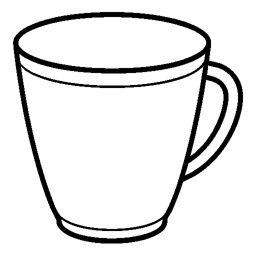

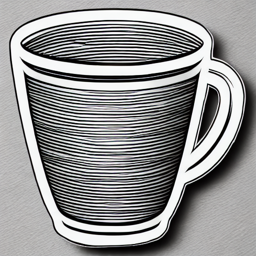

  0%|          | 0/30 [00:00<?, ?it/s]

✅ Clay guide saved: /content/final_demo/guides/gun_(3)_clay_guide.png

--- gun_(3) ---


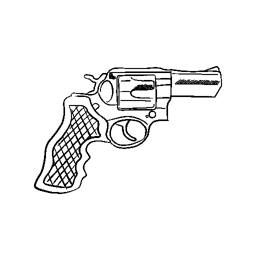

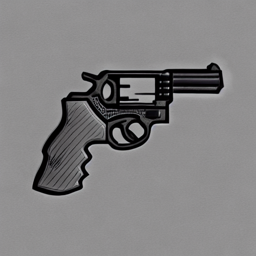


✅ All clay guides saved in: /content/final_demo/guides


In [14]:
from google.colab import files
from pathlib import Path
from IPython.display import display
import shutil

DEMO_ROOT = Path("/content/final_demo")
INPUT_DIR = DEMO_ROOT / "inputs"
GUIDE_DIR = DEMO_ROOT / "guides"

INPUT_DIR.mkdir(parents=True, exist_ok=True)
GUIDE_DIR.mkdir(parents=True, exist_ok=True)

print("Upload 1 to 4 single-object sketch images now.")
uploaded = files.upload()

if not uploaded:
    raise RuntimeError("No images uploaded.")

saved_inputs = []

for filename, data in uploaded.items():
    source = Path(filename)
    label = source.stem.lower().replace(" ", "_").replace("-", "_")

    destination = INPUT_DIR / f"{label}{source.suffix.lower()}"
    destination.write_bytes(data)
    saved_inputs.append((label, destination))

print("\nSaved input sketches:")
for label, path in saved_inputs:
    print(f"• {label}: {path}")

for label, sketch_path in saved_inputs:
    output_path = GUIDE_DIR / f"{label}_clay_guide.png"

    prompt = (
        f"a single centered realistic three-dimensional {label.replace('_', ' ')}, "
        "neutral gray clay material, product render, soft studio lighting"
    )

    guide, control = make_clay_guide(
        sketch_path=sketch_path,
        output_path=output_path,
        prompt=prompt,
        seed=2026,
    )

    print(f"\n--- {label} ---")
    display(control.resize((256, 256)))
    display(guide.resize((256, 256)))

print("\n✅ All clay guides saved in:", GUIDE_DIR)

In [15]:
import os
import gc
import json
import shutil
import subprocess
from pathlib import Path
import torch

# Release ControlNet GPU memory before SF3D loads.
del pipe
del controlnet
gc.collect()
torch.cuda.empty_cache()

print("ControlNet released.")
print("GPU allocated (MB):", round(torch.cuda.memory_allocated() / 1024**2, 1))

ROOT = Path("/content")
ENV = ROOT / "sf3d-env"
REPO = ROOT / "stable-fast-3d"
PY = ENV / "bin" / "python"

GUIDE_DIR = ROOT / "final_demo" / "guides"
GLB_DIR = ROOT / "final_demo" / "glb_models"
GLB_DIR.mkdir(parents=True, exist_ok=True)

run_env = os.environ.copy()
run_env["HF_HOME"] = str(ROOT / "hf-cache")
run_env["CUDA_HOME"] = str(ROOT / "cuda-12.1")
run_env["CUDA_PATH"] = str(ROOT / "cuda-12.1")
run_env["PATH"] = f"{ROOT / 'cuda-12.1' / 'bin'}:{ENV / 'bin'}:{run_env['PATH']}"
run_env["LD_LIBRARY_PATH"] = (
    f"{ROOT / 'cuda-12.1' / 'lib64'}:{ENV / 'lib'}:"
    + run_env.get("LD_LIBRARY_PATH", "")
)
run_env["TORCH_CUDA_ARCH_LIST"] = "7.5"

results = []

for guide_path in sorted(GUIDE_DIR.glob("*_clay_guide.png")):
    label = guide_path.name.replace("_clay_guide.png", "")
    work_dir = ROOT / "final_demo" / "sf3d_runs" / label

    print(f"\n{'=' * 72}")
    print(f"Generating SF3D model: {label}")
    print(f"{'=' * 72}")

    command = [
        str(PY),
        str(REPO / "run.py"),
        str(guide_path),
        "--output-dir", str(work_dir),
        "--texture-resolution", "512",
        "--remesh_option", "none",
    ]

    result = subprocess.run(
        command,
        cwd=str(REPO),
        env=run_env,
        text=True,
        capture_output=True,
    )

    print(result.stdout[-3000:])
    print(result.stderr[-2000:])

    generated_glb = work_dir / "0" / "mesh.glb"

    if result.returncode != 0 or not generated_glb.exists():
        results.append({
            "label": label,
            "status": "FAILED",
            "detail": f"SF3D return code: {result.returncode}",
        })
        print(f"❌ {label} failed")
        continue

    final_glb = GLB_DIR / f"{label}.glb"
    shutil.copy2(generated_glb, final_glb)

    mesh_check = subprocess.run(
        [
            str(PY), "-c",
            (
                "import trimesh, json, sys; "
                "m=trimesh.load(sys.argv[1], force='mesh'); "
                "print(json.dumps({'vertices':len(m.vertices),"
                "'faces':len(m.faces),'watertight':bool(m.is_watertight)}))"
            ),
            str(final_glb),
        ],
        env=run_env,
        text=True,
        capture_output=True,
        check=True,
    )

    metrics = json.loads(mesh_check.stdout.strip())
    metrics.update({
        "label": label,
        "status": "SUCCESS",
        "glb": str(final_glb),
        "size_mb": round(final_glb.stat().st_size / 1024**2, 3),
    })
    results.append(metrics)

    print(
        f"✅ {label}: {metrics['vertices']} vertices | "
        f"{metrics['faces']} faces | "
        f"watertight={metrics['watertight']} | "
        f"{metrics['size_mb']} MB"
    )

report_path = ROOT / "final_demo" / "sf3d_results.json"
report_path.write_text(json.dumps(results, indent=2))

print("\n" + "=" * 72)
print("FINAL SF3D RESULTS")
print("=" * 72)
for row in results:
    print(row)

print("\nGLBs saved in:", GLB_DIR)
print("Report:", report_path)

ControlNet released.
GPU allocated (MB): 9.1

Generating SF3D model: cup_outline_coloring_book_page_line_art_illustration_digital_drawing_871209_9844
Device used:  cuda
After Remesh 15302 30600
Peak Memory: 10460.76953125 MB

176M [00:00<00:02, 64.7MB/s]
 15%|█████▌                                | 25.9M/176M [00:00<00:02, 70.7MB/s]
 19%|███████                               | 33.0M/176M [00:00<00:02, 67.7MB/s]
 23%|████████▌                             | 39.8M/176M [00:00<00:02, 67.5MB/s]
 27%|██████████▎                           | 47.7M/176M [00:00<00:01, 71.2MB/s]
 31%|███████████▉                          | 55.3M/176M [00:00<00:01, 72.6MB/s]
 36%|█████████████▌                        | 62.5M/176M [00:00<00:01, 70.0MB/s]
 40%|███████████████▏                      | 70.4M/176M [00:01<00:01, 72.5MB/s]
 44%|████████████████▊                     | 77.7M/176M [00:01<00:01, 71.2MB/s]
 49%|██████████████████▍                   | 85.5M/176M [00:01<00:01, 73.2MB/s]
 53%|████████████████████

In [16]:
from pathlib import Path
from google.colab import files
import shutil
import json

ROOT = Path("/content")
DEMO_ROOT = ROOT / "final_demo"
PACKAGE_DIR = ROOT / "Sketch2Shape_Demo_Assets"

if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)

PACKAGE_DIR.mkdir()

# Copy saved source sketches, ControlNet guides, GLBs, and result metrics.
for folder_name in ["inputs", "guides", "glb_models"]:
    source = DEMO_ROOT / folder_name
    if source.exists():
        shutil.copytree(source, PACKAGE_DIR / folder_name)

report = DEMO_ROOT / "sf3d_results.json"
if report.exists():
    shutil.copy2(report, PACKAGE_DIR / "sf3d_results.json")

readme = PACKAGE_DIR / "README.txt"
readme.write_text(
    """Sketch2Shape AI — pre-generated demonstration assets

Pipeline:
raw sketch → ControlNet Scribble clay guide → official Stable Fast 3D → GLB

These GLB files were generated on a Google Colab Tesla T4 GPU.
They can be previewed in the project website using model-viewer.

Not included:
- Hugging Face token
- SF3D weights
- ControlNet weights
- CUDA/toolchain environment
"""
)

zip_path = Path(
    shutil.make_archive(
        str(ROOT / "Sketch2Shape_Demo_Assets"),
        "zip",
        root_dir=PACKAGE_DIR,
    )
)

print("✅ ZIP created:", zip_path)
print("Size (MB):", round(zip_path.stat().st_size / 1024**2, 2))

files.download(str(zip_path))

✅ ZIP created: /content/Sketch2Shape_Demo_Assets.zip
Size (MB): 4.42


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import json
import subprocess
import sys
from pathlib import Path
from google.colab import output
from IPython.display import display, HTML

ROOT = Path("/content")
DEMO_ROOT = ROOT / "final_demo"
GLB_DIR = DEMO_ROOT / "glb_models"
VIEWER_HTML = DEMO_ROOT / "viewer.html"

glbs = sorted(GLB_DIR.glob("*.glb"))

if not glbs:
    raise RuntimeError(f"No GLBs found in {GLB_DIR}")

items = [
    {
        "name": path.stem,
        "url": f"glb_models/{path.name}",
        "size_mb": round(path.stat().st_size / 1024**2, 3),
    }
    for path in glbs
]

viewer_html = f"""
<!doctype html>
<html>
<head>
  <meta charset="utf-8">
  <script type="module"
    src="https://unpkg.com/@google/model-viewer/dist/model-viewer.min.js">
  </script>
  <style>
    body {{
      margin: 0;
      min-height: 100vh;
      background: #121917;
      color: #edf4ef;
      font-family: Arial, sans-serif;
      padding: 24px;
    }}
    h1 {{ margin: 0 0 8px; font-size: 24px; }}
    p {{ color: #b7c6bd; }}
    select {{
      width: 100%;
      max-width: 620px;
      padding: 12px;
      border-radius: 8px;
      background: #1d2924;
      color: white;
      border: 1px solid #557365;
      margin: 12px 0 20px;
    }}
    model-viewer {{
      width: 100%;
      height: 620px;
      background: radial-gradient(circle at center, #33463d, #141d19 72%);
      border-radius: 16px;
      border: 1px solid #40594d;
    }}
    .details {{
      display: flex;
      gap: 12px;
      margin-top: 14px;
      color: #b7c6bd;
      font-size: 14px;
    }}
    code {{ color: #b8e7ce; }}
  </style>
</head>
<body>
  <h1>Sketch2Shape AI — 3D Demo Gallery</h1>
  <p>Drag to rotate · Scroll to zoom · Each model was generated with ControlNet → SF3D.</p>

  <select id="modelSelect"></select>

  <model-viewer
    id="viewer"
    camera-controls
    auto-rotate
    shadow-intensity="0.8"
    exposure="1"
    environment-image="neutral"
    interaction-prompt="auto">
  </model-viewer>

  <div class="details">
    <span id="name"></span>
    <span id="size"></span>
  </div>

  <script>
    const models = {json.dumps(items)};
    const select = document.getElementById("modelSelect");
    const viewer = document.getElementById("viewer");
    const name = document.getElementById("name");
    const size = document.getElementById("size");

    function showModel(index) {{
      const model = models[index];
      viewer.src = model.url;
      name.textContent = "Model: " + model.name;
      size.textContent = "Size: " + model.size_mb + " MB";
    }}

    models.forEach((model, index) => {{
      const option = document.createElement("option");
      option.value = index;
      option.textContent = model.name;
      select.appendChild(option);
    }});

    select.addEventListener("change", () => showModel(select.value));
    showModel(0);
  </script>
</body>
</html>
"""

VIEWER_HTML.write_text(viewer_html, encoding="utf-8")

# Serve /content so the viewer can load local GLB files.
PORT = 8000
server = subprocess.Popen(
    [sys.executable, "-m", "http.server", str(PORT), "--directory", str(ROOT)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL,
)

print("✅ Interactive gallery created.")
print("Models:")
for item in items:
    print(f"• {item['name']} — {item['size_mb']} MB")

output.serve_kernel_port_as_iframe(PORT, path="/final_demo/viewer.html")

✅ Interactive gallery created.
Models:
• cup_outline_coloring_book_page_line_art_illustration_digital_drawing_871209_9844 — 0.949 MB
• gun — 0.538 MB
• gun_(2) — 0.541 MB
• gun_(3) — 0.543 MB
• screenshot_2026_11_01_081330 — 0.471 MB


<IPython.core.display.Javascript object>